<a href="https://colab.research.google.com/github/sadhyasora-bit/Fraud-Detection_Model/blob/main/notebook/01_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Import Libraries & Dataset Loading

In [1]:
!pip install -q kagglehub

In [2]:
import kagglehub
import os

# Download dataset dari Kaggle
path = kagglehub.dataset_download("mlg-ulb/creditcardfraud")

print("Dataset berhasil diunduh!")
print("Lokasi dataset:", path)

# Periksa file dalam direktori
print("\nDaftar file:")
print(os.listdir(path))

Using Colab cache for faster access to the 'creditcardfraud' dataset.
Dataset berhasil diunduh!
Lokasi dataset: /kaggle/input/creditcardfraud

Daftar file:
['creditcard.csv']


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Membaca dataset
file_path = os.path.join(path, "creditcard.csv")
df = pd.read_csv(file_path)

print("Dataset berhasil dimuat!")

Dataset berhasil dimuat!


## 2. Exploratory Data Analysis (EDA)

In [4]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [5]:
df.tail()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
284802,172786.0,-11.881118,10.071785,-9.834783,-2.066656,-5.364473,-2.606837,-4.918215,7.305334,1.914428,...,0.213454,0.111864,1.014480,-0.509348,1.436807,0.250034,0.943651,0.823731,0.77,0
284803,172787.0,-0.732789,-0.055080,2.035030,-0.738589,0.868229,1.058415,0.024330,0.294869,0.584800,...,0.214205,0.924384,0.012463,-1.016226,-0.606624,-0.395255,0.068472,-0.053527,24.79,0
284804,172788.0,1.919565,-0.301254,-3.249640,-0.557828,2.630515,3.031260,-0.296827,0.708417,0.432454,...,0.232045,0.578229,-0.037501,0.640134,0.265745,-0.087371,0.004455,-0.026561,67.88,0
284805,172788.0,-0.240440,0.530483,0.702510,0.689799,-0.377961,0.623708,-0.686180,0.679145,0.392087,...,0.265245,0.800049,-0.163298,0.123205,-0.569159,0.546668,0.108821,0.104533,10.00,0
284806,172792.0,-0.533413,-0.189733,0.703337,-0.506271,-0.012546,-0.649617,1.577006,-0.414650,0.486180,...,0.261057,0.643078,0.376777,0.008797,-0.473649,-0.818267,-0.002415,0.013649,217.00,0


In [7]:
print("Jumlah baris   :", df.shape[0])
print("Jumlah kolom   :", df.shape[1])
print("Jumlah transaksi:", f"{df.shape[0]:,}")

Jumlah baris   : 284807
Jumlah kolom   : 31
Jumlah transaksi: 284,807


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [10]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Time,284807.0,9.481386e+04,47488.145955,0.000000,54201.500000,84692.000000,139320.500000,172792.000000
V1,284807.0,1.168375e-15,1.958696,-56.407510,-0.920373,0.018109,1.315642,2.454930
V2,284807.0,3.416908e-16,1.651309,-72.715728,-0.598550,0.065486,0.803724,22.057729
V3,284807.0,-1.379537e-15,1.516255,-48.325589,-0.890365,0.179846,1.027196,9.382558
V4,284807.0,2.074095e-15,1.415869,-5.683171,-0.848640,-0.019847,0.743341,16.875344
V5,284807.0,9.604066e-16,1.380247,-113.743307,-0.691597,-0.054336,0.611926,34.801666
V6,284807.0,1.487313e-15,1.332271,-26.160506,-0.768296,-0.274187,0.398565,73.301626
V7,284807.0,-5.556467e-16,1.237094,-43.557242,-0.554076,0.040103,0.570436,120.589494
V8,284807.0,1.213481e-16,1.194353,-73.216718,-0.208630,0.022358,0.327346,20.007208
V9,284807.0,-2.406331e-15,1.098632,-13.434066,-0.643098,-0.051429,0.597139,15.594995


In [12]:
missing_values = df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Percentage (%)": (missing_values / len(df)) * 100
})

missing_summary

,Missing Values,Percentage (%)
Time,0,0.0
V1,0,0.0
V2,0,0.0
V3,0,0.0
V4,0,0.0
V5,0,0.0
V6,0,0.0
V7,0,0.0
V8,0,0.0
V9,0,0.0


In [13]:
duplicate_count = df.duplicated().sum()

print("Jumlah data duplikat:", duplicate_count)
print(
    "Persentase duplikat:",
    round((duplicate_count / len(df)) * 100, 4),
    "%"
)

Jumlah data duplikat: 1081
Persentase duplikat: 0.3796 %


In [14]:
class_counts = df["Class"].value_counts().sort_index()

class_summary = pd.DataFrame({
    "Class": ["Non-Fraud", "Fraud"],
    "Jumlah Transaksi": [
        class_counts.get(0, 0),
        class_counts.get(1, 0)
    ],
})

class_summary["Persentase (%)"] = (
    class_summary["Jumlah Transaksi"] / len(df) * 100
)

class_summary

,Class,Jumlah Transaksi,Persentase (%)
0,Non-Fraud,284315,99.827251
1,Fraud,492,0.172749


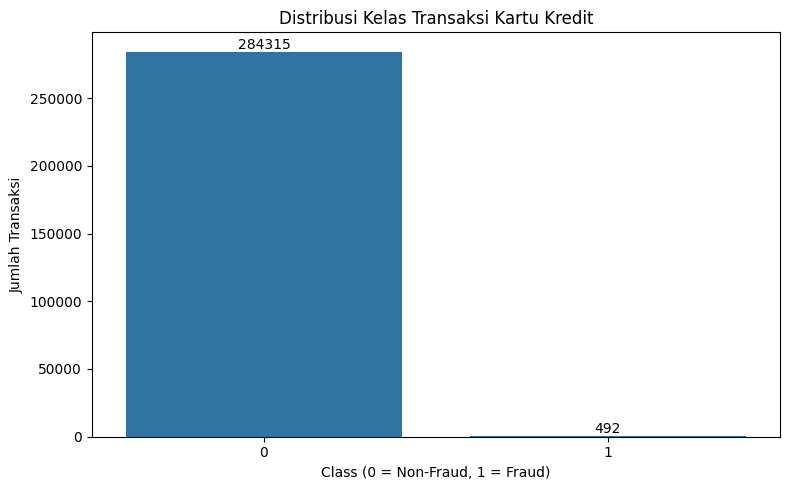

In [15]:
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x="Class"
)

plt.title("Distribusi Kelas Transaksi Kartu Kredit")
plt.xlabel("Class (0 = Non-Fraud, 1 = Fraud)")
plt.ylabel("Jumlah Transaksi")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f")

plt.tight_layout()
plt.show()

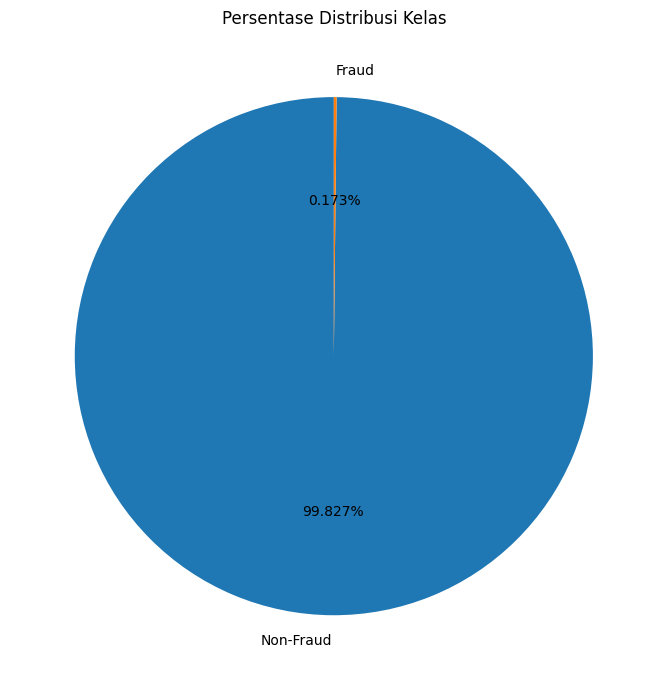

In [16]:
class_percentage = (
    df["Class"].value_counts(normalize=True).sort_index() * 100
)

plt.figure(figsize=(7, 7))

plt.pie(
    class_percentage,
    labels=["Non-Fraud", "Fraud"],
    autopct="%1.3f%%",
    startangle=90
)

plt.title("Persentase Distribusi Kelas")
plt.tight_layout()
plt.show()

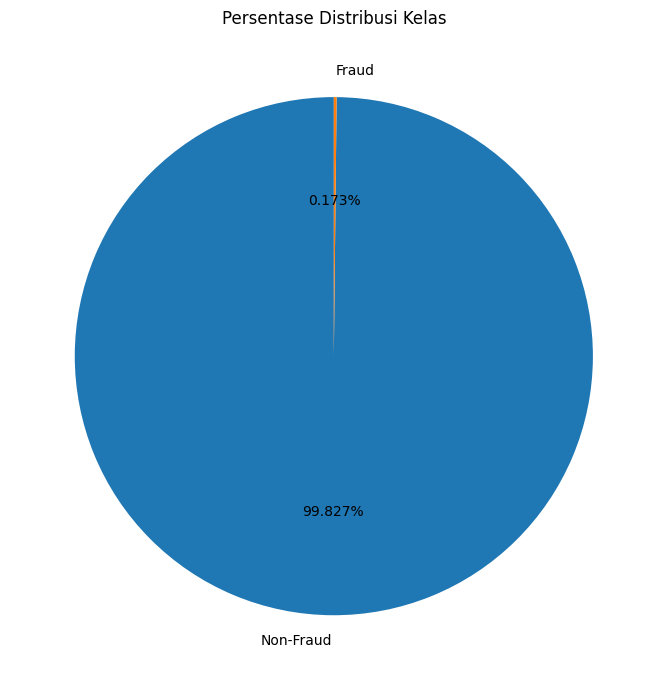

In [17]:
class_percentage = (
    df["Class"].value_counts(normalize=True).sort_index() * 100
)

plt.figure(figsize=(7, 7))

plt.pie(
    class_percentage,
    labels=["Non-Fraud", "Fraud"],
    autopct="%1.3f%%",
    startangle=90
)

plt.title("Persentase Distribusi Kelas")
plt.tight_layout()
plt.show()

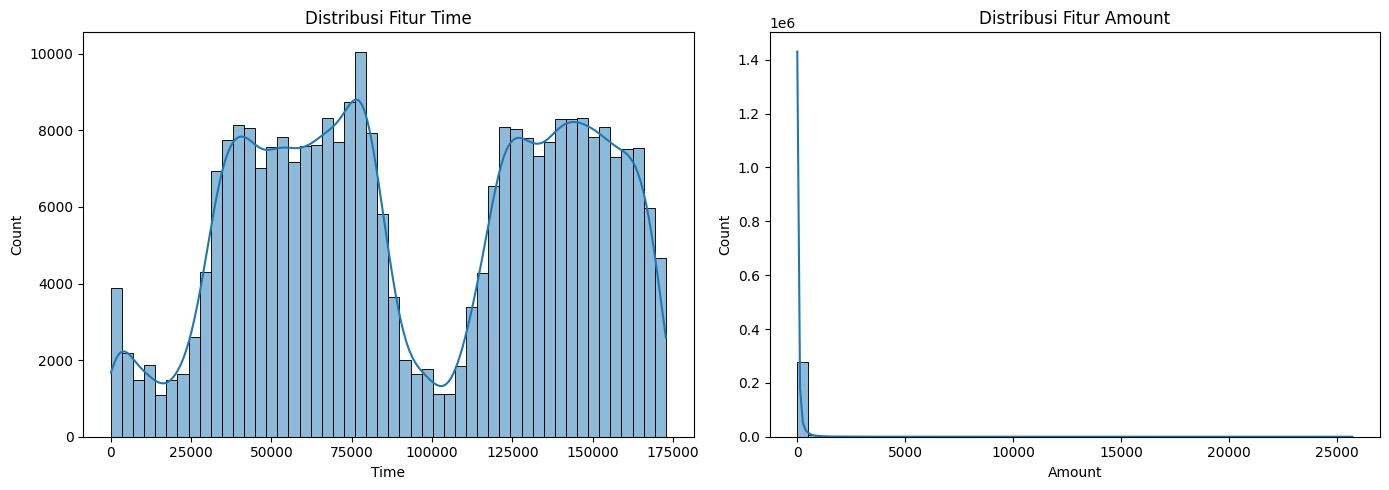

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    df["Time"],
    bins=50,
    kde=True,
    ax=axes[0]
)
axes[0].set_title("Distribusi Fitur Time")

sns.histplot(
    df["Amount"],
    bins=50,
    kde=True,
    ax=axes[1]
)
axes[1].set_title("Distribusi Fitur Amount")

plt.tight_layout()
plt.show()

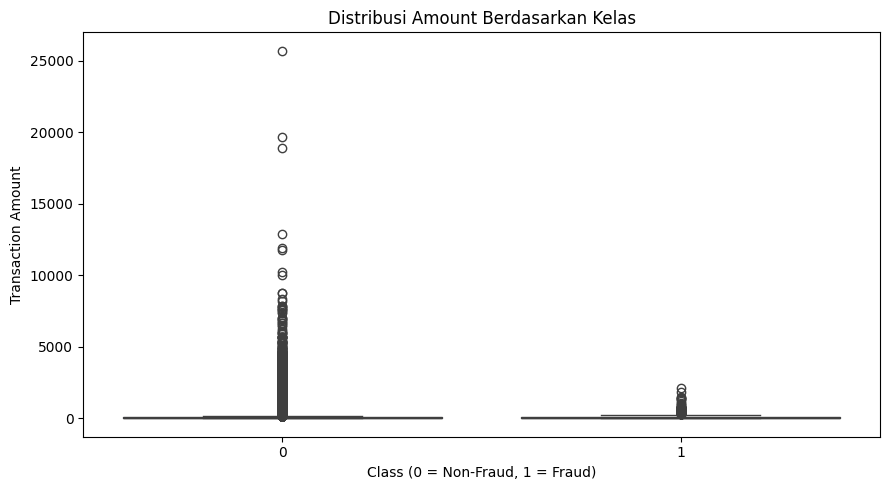

In [19]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Class",
    y="Amount"
)

plt.title("Distribusi Amount Berdasarkan Kelas")
plt.xlabel("Class (0 = Non-Fraud, 1 = Fraud)")
plt.ylabel("Transaction Amount")

plt.tight_layout()
plt.show()

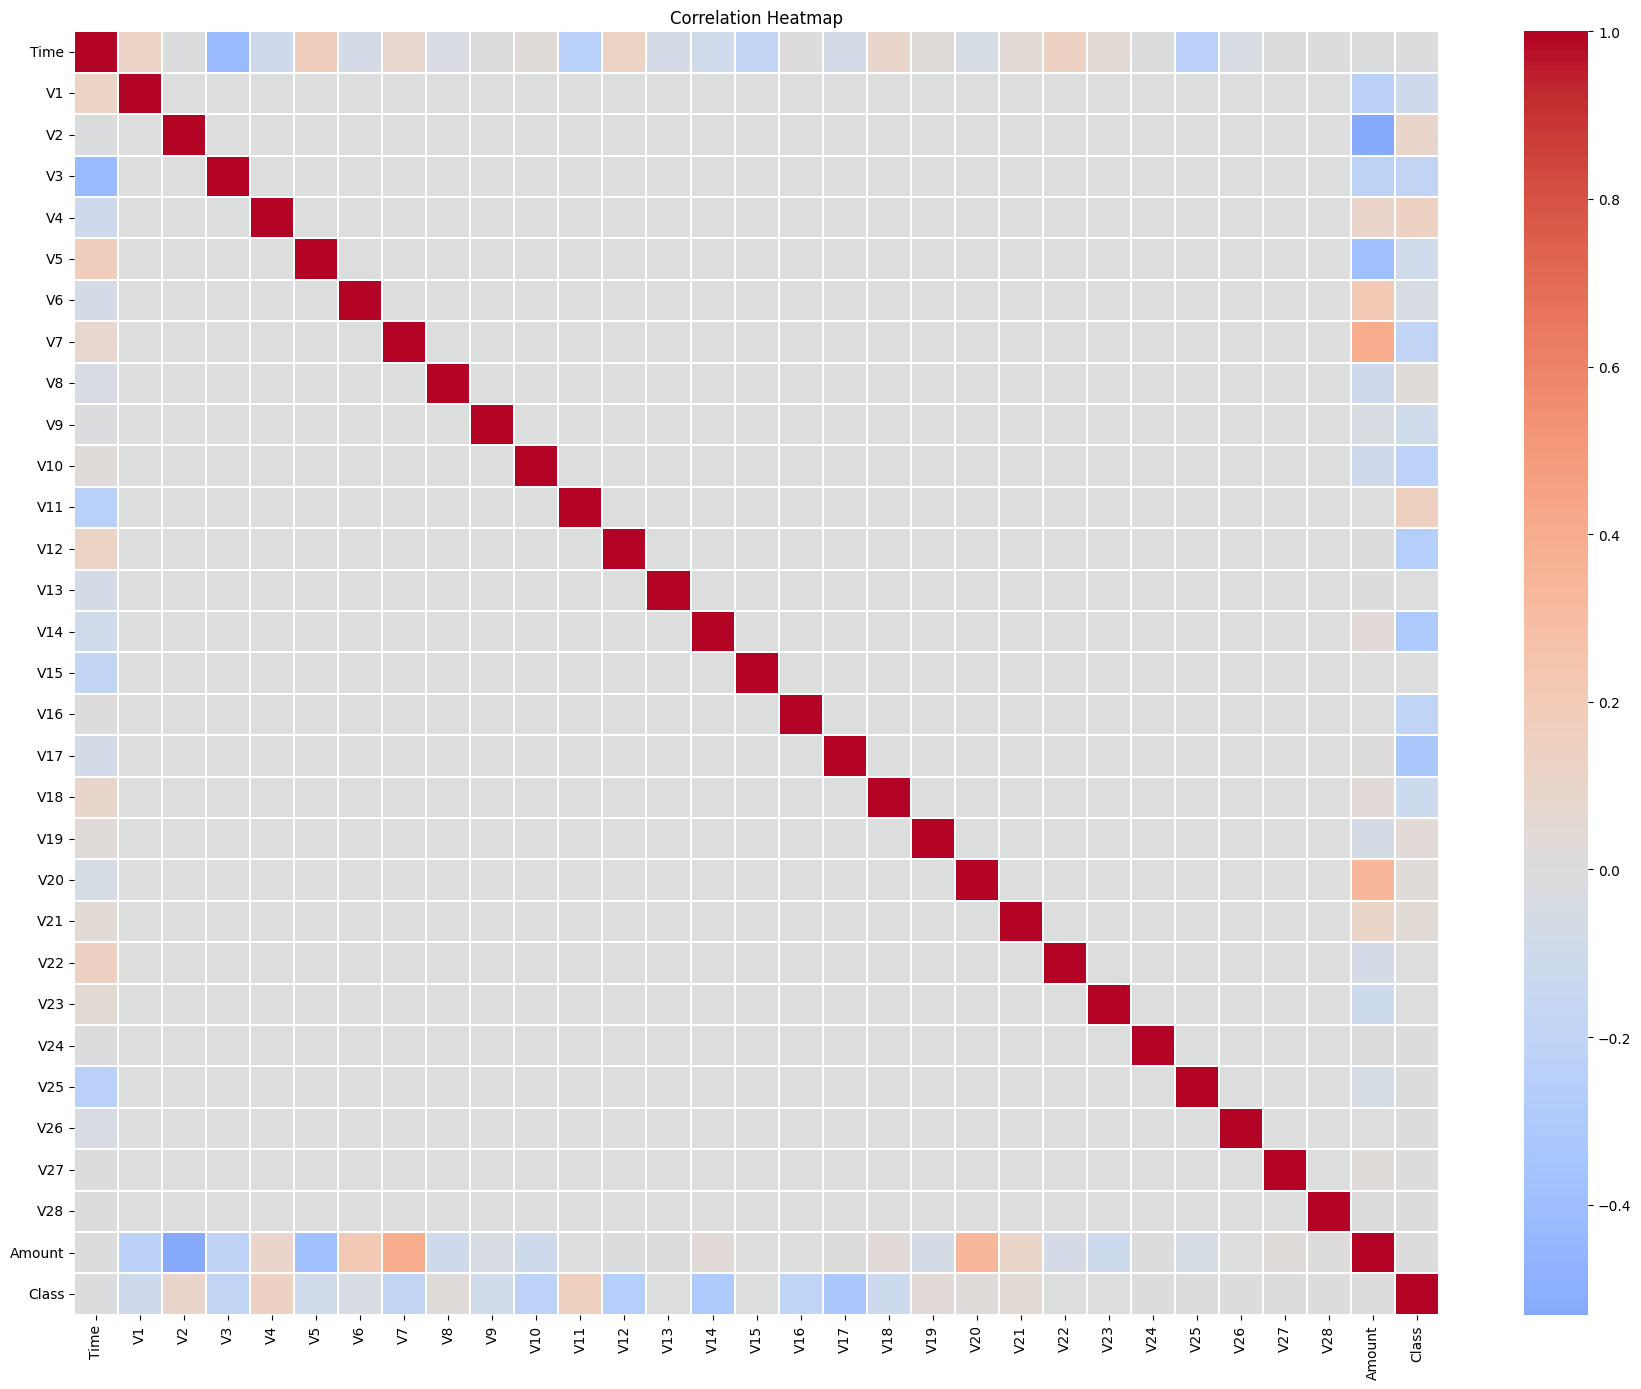

In [20]:
plt.figure(figsize=(18, 14))

correlation = df.corr()

sns.heatmap(
    correlation,
    cmap="coolwarm",
    center=0,
    linewidths=0.1
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()